# Estatística descritiva do corpus de poemas

Notebook com a análise descritiva dos poemas (`data/poemas.csv`), em três partes (a numeração das seções foi mantida):

- **1. Dados e visão geral**: carga do CSV.
- **2. Análise lexical**: tamanho dos poemas, frequências (total e documental) e nuvem de palavras, contando **lemas** ou **formas do texto**, conforme o parâmetro `LEMAS`.
- **4. Análise morfológica (spaCy)**: classes gramaticais e traços morfológicos (gênero, número, tempo, modo...).

Só o texto é analisado: os metadados não entram na análise.

**Corpus (parâmetro `CORPUS`):** `"poema"` analisa o CSV de poemas (`CSV_PATH`); `"carta"` analisa o JSONL de correspondências (`JSONL_PATH`), usando apenas as cartas com `idioma == IDIOMA` e apenas o campo `texto_diplomatico`. Nas cartas, o texto é limpo antes da análise (marcas `[Página N]` removidas, `[ilegível]` contado e trocado por `…`, hifenização de fim de linha desfeita) e as cartas com pouco texto legível podem ser descartadas. Os nomes que dizem "poema" (`metricas_por_poema`, `por_poema`...) valem para os dois corpora.

**Como usar:** edite os parâmetros na primeira célula de código e rode tudo (*Run All*). Todas as tabelas (`.csv`) e figuras (`.png`) também são salvas na pasta `SAIDA`. A parte 4 precisa de spaCy; se não tiver, defina `RODAR_SPACY = False` e o restante roda normalmente.

**Glossário rápido**

| Termo | Significado |
|---|---|
| token / palavra | sequência de letras (sem pontuação nem dígitos) |
| tipo | palavra distinta; vocabulário = conjunto de tipos |
| lema | forma de dicionário da palavra ("águas" → "água"); com `LEMAS = True`, a parte 2 conta lemas |
| freq | nº de ocorrências totais da palavra no corpus |
| df | frequência documental: nº de **poemas** (ou **cartas**) em que a palavra aparece |
| UPOS | classe gramatical universal (NOUN, VERB, ADJ, ...) |

In [10]:
# %pip install pandas numpy matplotlib scipy spacy wordcloud
# !python -m spacy download pt_core_news_lg

## 0. Configuração e parâmetros

In [11]:
from __future__ import annotations

import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ===================== PARÂMETROS (edite aqui) =====================
CORPUS = "carta"                    # "poema" (CSV de poemas) ou "carta" (JSONL de correspondências)
CSV_PATH = "data/poemas.csv"        # caminho do CSV (CORPUS = "poema")
JSONL_PATH = "data/OCR_normalizado.jsonl"   # caminho do JSONL (CORPUS = "carta")
SAIDA = Path("output/descritiva")   # pasta onde tabelas e figuras são salvas
TOP = 30                            # tamanho dos rankings de palavras
RODAR_SPACY = True                  # False pula a parte 4 (não precisa de spaCy)
LEMAS = True                        # True: a análise lexical (parte 2) conta lemas em vez das formas do texto (requer spaCy)
FONTE_NUVEM = None                  # ex.: "impact.ttf" (None = fonte padrão da nuvem)
CLASSES = None                      # ex.: ["NOUN", "VERB", "ADJ"]; None = todas as classes
CLASSES_EXIBIR = ["NOUN", "VERB", "ADJ", "ADV"]   # classes mostradas aqui; as demais só são salvas (None = todas)
USAR_FORMAS = False                 # True: contar formas do texto em vez de lemas (por classe)
CLASSES_SEM_STOP = False            # True: excluir stopwords do spaCy nas análises por classe
MIN_PALAVRAS_CLASSE = 10            # mínimo de palavras para gerar as figuras de uma classe

# --- só para CORPUS = "carta" ---
IDIOMA = "pt"                       # só entram cartas com este valor no campo 'idioma'
MIN_PALAVRAS_LEGIVEIS = 10          # descarta cartas com menos palavras legíveis que isto (0 = não descarta)
MAX_PROP_ILEGIVEL = 0.5             # descarta cartas com proporção de [ilegível] maior que isto (None = não descarta)
JUNTAR_HIFENS = True                # junta palavras hifenizadas na quebra de linha/página ("pro-\nblema" -> "problema")
NORMALIZAR_MAIUSCULAS = None        # None = automático (poema: True; carta: False); ver texto_para_spacy
# ===================================================================

if CORPUS not in ("poema", "carta"):
    raise ValueError('CORPUS deve ser "poema" ou "carta".')
NOME_DOC = "poemas" if CORPUS == "poema" else "cartas"      # usado em títulos e rótulos
if NORMALIZAR_MAIUSCULAS is None:
    NORMALIZAR_MAIUSCULAS = (CORPUS == "poema")
if CORPUS == "carta":
    SAIDA = SAIDA.with_name(SAIDA.name + "_cartas")         # não sobrescreve a saída dos poemas

SAIDA.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
plt.rcParams["figure.dpi"] = 100

## Funções: carga e tokenização

- A **tokenização** aceita apenas letras (com hífen/apóstrofo internos, ex.: `sê-lo`) e converte para minúsculas. Pontuação e dígitos são ignorados.
- As **stopwords** (palavras funcionais: artigos, preposições, conjunções, pronomes...) são a lista abaixo, unida à do spaCy quando ele está instalado. Revise a lista: palavras como "mais" ou "já" podem interessar à análise.

In [12]:
# Stopwords do português (palavras funcionais).
STOPWORDS_PT = set("""
a o as os um uma uns umas de do da dos das dum duma duns dumas em no na nos nas num numa nuns numas
por pelo pela pelos pelas per para pra com sem sob sobre entre até ante após contra desde perante
e ou mas porém contudo todavia senão nem que se como quando porque pois porquanto embora conquanto
eu tu ele ela nós vós eles elas me te lhe lhes nos vos mim ti si comigo contigo consigo
meu minha meus minhas teu tua teus tuas seu sua seus suas nosso nossa nossos nossas
este esta estes estas esse essa esses essas aquele aquela aqueles aquelas isto isso aquilo
ao aos à às ali aqui aí lá cá onde
é são era eram foi foram ser sendo sido está estão estava estavam estar
há havia haver tem têm tinha tinham ter
já mais muito muita muitos muitas
""".split())

# Palavras = sequências de letras (com hífen/apóstrofo internos). Ignora pontuação e dígitos.
TOKEN_RE = re.compile(r"[^\W\d_]+(?:[-'’][^\W\d_]+)*", re.UNICODE) #transformando em um objeto de expressão regular
SENT_RE = re.compile(r"[.!?…]+")

COLUNAS_META = ["ano", "tecnica", "local", "colecao", "local_poema", "ano_poema", "mes_poema", "dia_poema"]


def carregar(caminho: Path) -> pd.DataFrame:
    df = pd.read_csv(caminho, encoding="utf-8")
    if "estrofes" not in df.columns:
        raise SystemExit("Coluna 'estrofes' não encontrada no CSV.")
    if "id" not in df.columns:
        df["id"] = [f"poema_{i + 1:03d}" for i in range(len(df))]
    df["estrofes"] = (     #limpeza, substituindo Nan por "", substitui ada sequência de um ou mais caracteres de espaço em branco por um único espaço.
        df["estrofes"].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    )
    df["tokens"] = df["estrofes"].map(tokenizar) #é criado uma nova coluna no df "tokens" que possui os estrofes tokenizados
    return df


def tokenizar(texto: str) -> list[str]:             #normalizando deixando tudo em minúsculo
    return [t.lower() for t in TOKEN_RE.findall(texto)]


def carregar_stopwords() -> set[str]:
    stop = set(STOPWORDS_PT)                #evitar duplicata
    try:
        from spacy.lang.pt.stop_words import STOP_WORDS

        stop |= {w.lower() for w in STOP_WORDS} #tentar adicionar as stop words do spacy (normalizado em minúsculo)
    except Exception:
        pass
    return stop

### Funções: carga das cartas (JSONL)

Só usadas com `CORPUS = "carta"`. `carregar_cartas` devolve o mesmo esquema de `carregar` (colunas `id`, `estrofes`, `tokens`), mais `n_ilegiveis`, `prop_ilegivel` e `n_paginas`, e a lista de cartas descartadas.

- Mantém só `idioma == IDIOMA` e usa apenas `texto_diplomatico`.
- `limpar_texto_diplomatico`: remove `[Página N]`; junta palavras hifenizadas na quebra de linha (opcional); conta e troca cada `[ilegível]` por `…`.
- Descarta cartas com poucas palavras legíveis ou muitas ilegíveis (parâmetros), e salva a lista.


In [ ]:
PAGINA_RE = re.compile(r"\[\s*p[áa]gina\s*\d+\s*\]", re.IGNORECASE)      # marca de página: [Página 1]
ILEGIVEL_RE = re.compile(r"\[\s*ileg[íi]vel\s*\]", re.IGNORECASE)      # trecho ilegível __ [texto ilegível] ___ [illegible]
HIFEN_QUEBRA_RE = re.compile(r"(\w)-[ \t]*\n\s*(\w)")                 # "pro-\nblema"
COLCHETES_RE = re.compile(r"\[[^\]]*\]")                              # qualquer marcação entre colchetes
LACUNAS_RE = re.compile(r"(?:…\s*){2,}")                               # várias lacunas seguidas
# ARQ_3800_2d10360a93d1acc27dc5189f29596760.jpeg o texto é claramente em inglês mas está classificado com "pt"

def limpar_texto_diplomatico(texto: str, juntar_hifens: bool = True) -> tuple[str, int]:
    """Limpa o texto diplomático de uma carta. Retorna (texto limpo, nº de [ilegível]).

    Ordem: tira as marcas de página (trocadas por quebra de linha); junta hifenização de fim de
    linha; conta os [ilegível] e troca cada um por '…' (pontuação, que o tokenizador ignora e que
    evita colar as palavras vizinhas); funde lacunas seguidas e normaliza os espaços.
    """
    texto = PAGINA_RE.sub("\n", texto)
    if juntar_hifens:
        texto = HIFEN_QUEBRA_RE.sub(r"\1\2", texto)
    n_ileg = len(ILEGIVEL_RE.findall(texto))
    texto = ILEGIVEL_RE.sub(" … ", texto)
    texto = LACUNAS_RE.sub("… ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto, n_ileg


def carregar_cartas(caminho, idioma="pt", juntar_hifens=True, min_palavras=0, max_prop_ileg=None):
    """Lê o JSONL de correspondências. Retorna (df das cartas mantidas, df das descartadas)."""
    registros, invalidas = [], []
    with open(caminho, encoding="utf-8") as f:
        for n, linha in enumerate(f, 1):
            linha = linha.strip()
            if not linha:
                continue
            try:
                registros.append(json.loads(linha))
            except json.JSONDecodeError:
                invalidas.append(n)
    raw = pd.DataFrame(registros)
    for col in ("id_documento", "idioma", "texto_diplomatico"):
        if col not in raw.columns:
            raise SystemExit(f"Campo '{col}' não encontrado no JSONL.")
    print(f"  {len(raw)} registros lidos; linhas inválidas: {invalidas or 'nenhuma'}")
    print("  idioma (todos os registros):", raw["idioma"].value_counts(dropna=False).to_dict())

    lang = raw["idioma"].astype("string").str.strip().str.lower()
    raw = raw[(lang == idioma.lower()).fillna(False)].copy()
    print(f"  {len(raw)} registros com idioma == '{idioma}'")

    dup = int(raw["id_documento"].duplicated().sum())
    if dup:
        print(f"  {dup} id_documento duplicados: mantida a primeira ocorrência de cada um.")
        raw = raw.drop_duplicates("id_documento", keep="first")

    textos = raw["texto_diplomatico"].fillna("").astype(str)
    res = [limpar_texto_diplomatico(t, juntar_hifens) for t in textos]

    # marcações entre colchetes que não são tratadas (viram palavras): só informa
    outros = Counter()
    for t in textos:
        outros.update(m.lower() for m in COLCHETES_RE.findall(ILEGIVEL_RE.sub("", PAGINA_RE.sub("", t))))
    if outros:
        print("  outras marcações entre colchetes (NÃO tratadas):", outros.most_common(10))

    df = pd.DataFrame(
        {
            "id": raw["id_documento"].astype(str).values,
            "estrofes": [t for t, _ in res],          # coluna com o texto, como em carregar()
            "n_ilegiveis": [n for _, n in res],
            "n_paginas": raw["num_paginas"].values if "num_paginas" in raw.columns else np.nan,
        }
    )
    df["tokens"] = df["estrofes"].map(tokenizar)
    n_pal = df["tokens"].map(len)
    total = n_pal + df["n_ilegiveis"]
    df["prop_ilegivel"] = np.where(total > 0, df["n_ilegiveis"] / total.where(total > 0, 1), np.nan)

    if "total_ilegiveis" in raw.columns:
        campo = pd.to_numeric(raw["total_ilegiveis"], errors="coerce").values
        n_div = int((campo != df["n_ilegiveis"].values).sum())
        print(f"  total_ilegiveis do JSONL difere da contagem no texto (ou está ausente) em {n_div} cartas (usada: a do texto)")

    manter = n_pal >= min_palavras
    if max_prop_ileg is not None:
        manter &= ~(df["prop_ilegivel"] > max_prop_ileg)
    descartadas = df.loc[~manter, ["id", "n_ilegiveis", "prop_ilegivel"]].assign(n_palavras=n_pal[~manter])
    print(f"  descartadas por qualidade: {len(descartadas)}; mantidas: {int(manter.sum())}")
    return df[manter].reset_index(drop=True), descartadas.reset_index(drop=True)


## Funções: métricas e frequências

- `metricas_por_poema`: tokens, tipos, comprimento médio da palavra, sentenças e proporção de palavras funcionais, por poema.
- `tabela_frequencias`: `freq` (ocorrências totais) e `df` (nº de poemas) de cada palavra.
- `resumo_global`: números gerais do corpus (vocabulário, estatísticas do tamanho dos poemas). Por enquanto fica de lado (ver seção 1).
- `resumo_metadados`: valores faltantes e contagens por coluna de metadados (por enquanto não usado).

In [14]:

# retorna uma tabela onde cada linha corresponde a um poema e possui um dicionário com as métricas

def metricas_por_poema(df: pd.DataFrame, stop: set[str]) -> pd.DataFrame:
    linhas = []                     #zip, combina os elementos de difernetes colunas
    for pid, texto, toks in zip(df["id"], df["estrofes"], df["tokens"]):
        n = len(toks)
        tipos = len(set(toks))
        sentencas = [s for s in SENT_RE.split(texto) if s.strip()] #dividito por .!?…
        conteudo = [t for t in toks if t not in stop]               #palavras que não são stopwords
        linhas.append(
            {
                "id": pid,                              
                "n_caracteres": len(texto),     #número de caracteres    
                "n_tokens": n,                  #número de palavras
                "n_tipos": tipos,               #número de plavras diferentes
                "comp_medio_palavra": np.mean([len(t) for t in toks]) if n else np.nan,
                "n_sentencas": len(sentencas),      
                "tokens_por_sentenca": n / len(sentencas) if sentencas else np.nan,
                "n_tokens_conteudo": len(conteudo),
                "prop_funcionais": 1 - len(conteudo) / n if n else np.nan, #proporção de stopwords
            }
        )
    return pd.DataFrame(linhas)

# retorna uma tabela com palavra, frequência, df (quantidade de diferentes poemas em que a palavra aparece) em ordem decrscente de frequencia e df
def tabela_frequencias(tokens_por_poema, stop: set[str] | None = None) -> pd.DataFrame:
    """freq = ocorrências totais; df = nº de poemas em que a palavra aparece."""
    tf, dfc = Counter(), Counter() # Counter({'gato': 3, 'cão': 2, 'pássaro': 1}), ou seja counter é um dicionário feito para contar
    for toks in tokens_por_poema: #passa por todos os poemas
        if stop:
            toks = [t for t in toks if t not in stop] # inclui as palavras do poema, menos as stopwords
        tf.update(toks)             #conta a ocorrencia de palavras 
        dfc.update(set(toks))       #conta a ocrrencia de palavras distintos, ou seja uma palavra é 1 ou 0 para cada poema
    tab = pd.DataFrame({"palavra": list(tf), "freq": list(tf.values())}) #fazendo uma tabela com a palavra e a sua frequência
    tab["df"] = tab["palavra"].map(dfc) # df vai que a quantidade de poemas diferenes em que cada palavra aparece
    tab = tab.sort_values(["freq", "df", "palavra"], ascending=[False, False, True]).reset_index(drop=True) #ordem decrescente
    tab["rank"] = tab.index + 1
    return tab

# pega o df, metrica por poema, e a frequencia com e sem stopwords. Retorna um dicionário com as "estatísticas"
def resumo_global(df, por_poema, freq_total, freq_conteudo) -> pd.Series:
    n_tokens = int(por_poema["n_tokens"].sum())
    V = len(freq_total)
    return pd.Series(
        {
            "n_poemas": len(df),
            "n_poemas_vazios": int((por_poema["n_tokens"] == 0).sum()),
            "n_tokens_total": n_tokens,
            "n_tipos (vocabulário)": V,
            "tipos de conteúdo (sem stopwords)": len(freq_conteudo),
            "tokens de conteúdo": int(freq_conteudo["freq"].sum()),
            "prop. tokens funcionais": 1 - freq_conteudo["freq"].sum() / n_tokens if n_tokens else np.nan,
            "tokens/poema: média": por_poema["n_tokens"].mean(),
            "tokens/poema: mediana": por_poema["n_tokens"].median(),
            "tokens/poema: desvio-padrão": por_poema["n_tokens"].std(),
            "tokens/poema: mín": por_poema["n_tokens"].min(),
            "tokens/poema: máx": por_poema["n_tokens"].max(),
            "tokens/sentença: média": por_poema["tokens_por_sentenca"].mean(),
            "comprimento médio da palavra": np.average(
                por_poema["comp_medio_palavra"].fillna(0), weights=por_poema["n_tokens"].clip(lower=1)
            ),
        },
        dtype=object,
    )


def resumo_metadados(df: pd.DataFrame, top: int = 15) -> dict[str, pd.DataFrame]:
    out = {}
    faltantes = df.drop(columns=["tokens"], errors="ignore").isna().mean().rename("prop_faltante").to_frame()
    out["faltantes"] = faltantes
    for col in COLUNAS_META:
        if col in df.columns:
            vc = df[col].value_counts(dropna=False).head(top).rename_axis(col).reset_index(name="n")
            out[col] = vc
    return out

## Funções: figuras

Cada função salva o `.png` em `SAIDA` e exibe a figura no notebook (`mostrar=False` só salva).

In [15]:
def finalizar(fig, caminho=None, mostrar=True):
    """Salva a figura (se houver caminho) e a exibe no notebook."""
    fig.tight_layout()
    if caminho is not None:
        fig.savefig(caminho, dpi=150, bbox_inches="tight")
    if mostrar:
        plt.show()
    else:
        plt.close(fig)


def fig_top_palavras(tab, titulo, caminho, top, mostrar=True):
    """Barras das `top` palavras: frequência total (azul) e nº de poemas (laranja)."""
    t = tab.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(t) + 1.5))
    ax.barh(t["palavra"], t["freq"], color="#4C72B0", label="frequência total")
    ax.barh(t["palavra"], t["df"], color="#DD8452", height=0.4, label=f"nº de {NOME_DOC} (df)")
    ax.set_title(titulo)
    ax.set_xlabel("contagem")
    ax.legend(loc="lower right")
    finalizar(fig, caminho, mostrar)


PALETA_NUVEM = ["#F2389E", "#7660A6", "#049DD9", "#C5D932", "#F2B705"]


def nuvem_de_frequencias(contagem, caminho=None, fonte=None, seed=42, max_palavras=150,
                         titulo=None, mostrar=True):
    """Nuvem a partir de uma Series (índice = palavra, valor = frequência).
    Paleta e semente fixas: o resultado é reprodutível."""
    try:
        import random

        from wordcloud import WordCloud
    except ImportError:
        print("wordcloud não instalado (%pip install wordcloud): nuvem ignorada.")
        return None
    freq = {str(k): int(v) for k, v in contagem.items() if v > 0}
    if not freq:
        return None
    if fonte and not Path(fonte).exists():
        print(f"fonte '{fonte}' não encontrada: usando a fonte padrão da nuvem.")
        fonte = None
    rng = random.Random(seed)

    def cor(*args, **kwargs):
        return rng.choice(PALETA_NUVEM)

    wc = WordCloud(
        width=1400, height=800, background_color="white", max_words=max_palavras,
        collocations=False, font_path=fonte, prefer_horizontal=0.8, random_state=seed,
        color_func=cor,
    ).generate_from_frequencies(freq)
    if caminho is not None:
        wc.to_file(str(caminho))
    if mostrar:
        fig, ax = plt.subplots(figsize=(12, 7))
        ax.imshow(wc, interpolation="bilinear")
        ax.axis("off")
        if titulo:
            ax.set_title(titulo)
        plt.tight_layout()
        plt.show()
    return wc

## Funções: spaCy (lemas, classes gramaticais e traços)

Obtêm, de cada palavra, o **lema**, a **classe gramatical (UPOS)** e os **traços morfológicos**. Ficam aqui, antes da parte 1, porque com `LEMAS = True` a análise lexical (parte 2) também usa os lemas; a parte 4 usa a mesma tabela. Os pontos de atenção estão no início da parte 4.

In [16]:
def texto_para_spacy(texto: str, normalizar_maiusculas: bool = True) -> str:
    """Prepara o texto para a análise morfológica com spaCy.

    As letras maiúsculas são convertidas para minúsculas, exceto
    aquelas que iniciam uma frase após os sinais '.', '!', '?' ou '…'.

    Essa padronização busca reduzir possíveis erros na categorização
    morfológica, pois os poemas apresentam letras maiúsculas no início
    dos versos, mesmo quando não há início de uma nova frase. Essa
    capitalização pode levar o spaCy a classificar palavras comuns
    incorretamente como nomes próprios (PROPN).

    A capitalização após o fim de uma frase é preservada para manter
    essa informação como uma possível pista para a análise morfológica.

    As barras '/' são substituídas por espaços, mesmo que não existam
    deixado para um futuro próximo.

    Com normalizar_maiusculas=False (usado nas cartas), nenhuma maiúscula é alterada:
    o texto diplomático quase não tem pontuação, então a regra acima rebaixaria quase
    todas as maiúsculas e os nomes próprios (Maria, Belo Horizonte) deixariam de ser
    reconhecidos como PROPN. Só a troca de '/' e de espaços é feita.
    """
    texto = texto.replace("/", " ")
    texto = re.sub(r"\s+", " ", texto).strip()
    if not normalizar_maiusculas:
        return texto

    # (^|[.!?…]\s*)? casa o início do texto ou a pontuação final (+ espaços) antes da maiúscula;
    # se casou (group(1) não é None), é início de frase e a letra é preservada
    return re.sub(
        r"(^|[.!?…]\s*)?\b[A-ZÁÀÂÃÉÊÍÓÔÕÚÇ]",
        lambda m: m.group() if m.group(1) is not None else m.group().lower(),
        texto
    )


def carregar_modelo_spacy():
    try:
        import spacy
    except ImportError:
        print("  spaCy não instalado. Para POS/morfologia: pip install spacy && "
              "python -m spacy download pt_core_news_lg")
        return None
    for modelo in ("pt_core_news_lg", "pt_core_news_md", "pt_core_news_sm"):
        try:
            nlp = spacy.load(modelo, disable=["ner", "parser"])
            print(f"  modelo spaCy: {modelo}")
            return nlp
        except OSError:
            continue
    print("  Nenhum modelo pt_core_news_* encontrado: python -m spacy download pt_core_news_lg")
    return None

PALAVRA_RE = re.compile(
    r"^[^\W\d_]+(?:[-'’][^\W\d_]+)*$",
    re.UNICODE
)
def tokens_spacy(df: pd.DataFrame, normalizar_maiusculas: bool = True) -> pd.DataFrame | None:
    """Uma linha por palavra: id do poema, token, lema, pos (UPOS),
    morph e is_stop."""

    nlp = carregar_modelo_spacy()
    if nlp is None:
        return None

    textos = df["estrofes"].map(lambda t: texto_para_spacy(t, normalizar_maiusculas)).tolist()
    registros = []

    for pid, doc in zip(df["id"], nlp.pipe(textos, batch_size=16)):
        for t in doc:
            # Aceita palavras com hífens e apóstrofos, como "bem-estar"
            # e "d'água", que seriam excluídas por t.is_alpha.
            # Pontuação isolada e números continuam sendo ignorados.
            if not PALAVRA_RE.fullmatch(t.text):
                continue                        
            registros.append(                   #o contexto usado nesse caso foi o poema todo onde o token pertence
                {
                    "id": pid,                 # Identificador do poema ao qual a palavra pertence.
                    "token": t.text.lower(),   # Forma original do token, convertida para minúsculas.
                    "lema": t.lemma_.lower(), # Lema: forma de dicionário da palavra, em minúsculas.
                    "pos": t.pos_,             # Categoria gramatical (UPOS), como NOUN, VERB, ADJ e PROPN.
                    "morph": str(t.morph),     # Traços morfológicos, como Gender=Masc e Number=Sing.
                    "is_stop": bool(t.is_stop),# Indica se o spaCy considera o token uma stopword.
                }
            )

    return pd.DataFrame(registros)

#pega a coluna morph, que contém várias características morfológicas em uma única célula, e separa cada característica em uma linha própria.
def explodir_tracos(tok: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por (palavra, traço): colunas traco ('Number=Sing'), feature ('Number'), value ('Sing')."""
    m = tok.assign(traco=tok["morph"].str.split("|")).explode("traco")
    m = m[m["traco"].notna() & (m["traco"] != "")].copy()
    m[["feature", "value"]] = m["traco"].str.split("=", n=1, expand=True)
    return m


def lemas_por_poema(tok: pd.DataFrame, df: pd.DataFrame) -> pd.Series:
    """Lista de lemas de cada poema (na ordem do texto), alinhada às linhas de df.

    Usada na análise lexical com LEMAS = True. Lemas de contrações vêm com espaço
    ('em o', 'de ela'); são separados nas palavras componentes ('em', 'o').
    """
    por_id = {
        pid: [w for lema in lemas for w in lema.split()]
        for pid, lemas in tok.groupby("id", sort=False)["lema"]
    }
    return pd.Series([por_id.get(pid, []) for pid in df["id"]], index=df.index, dtype=object)

## 1. Dados e visão geral

In [17]:
if CORPUS == "poema":
    df = carregar(CSV_PATH)
else:
    df, descartadas = carregar_cartas(
        JSONL_PATH, IDIOMA, JUNTAR_HIFENS, MIN_PALAVRAS_LEGIVEIS, MAX_PROP_ILEGIVEL
    )
    descartadas.to_csv(SAIDA / "cartas_descartadas.csv", index=False)
stop = carregar_stopwords()

print(f"{len(df)} {NOME_DOC}; colunas: {list(df.columns.drop('tokens'))}")

  3809 registros lidos; linhas inválidas: nenhuma
  idioma (todos os registros): {'pt': 2543, 'en': 501, 'fr': 292, 'es': 240, 'it': 227, 'ru': 3, 'de': 1, 'sv': 1, 'zh': 1}
  2543 registros com idioma == 'pt'
  outras marcações entre colchetes (NÃO tratadas): [('[illegible]', 477), ('[assinatura ilegível]', 80), ('[assinatura]', 37), ('[assinatura manuscrita]', 10), ('[assinatura illegível]', 7), ('[?]', 4), ('[início de texto manuscrito ilegível]', 1), ('[fornecimento?]', 1), ('[\n    "mento dos correios e telegrafos",\n    "telegrama",\n    "imprensa nacional 14/61"\n  ]', 1), ('[\n    "co-2291",\n    "recebido: [assinatura ilegível]', 1)]
  total_ilegiveis do JSONL difere da contagem no texto (ou está ausente) em 208 cartas (usada: a do texto)
  descartadas por qualidade: 108; mantidas: 2435
2435 cartas; colunas: ['id', 'estrofes', 'n_ilegiveis', 'n_paginas', 'prop_ilegivel']


### Unidade da análise lexical: formas ou lemas

Com `LEMAS = True` (parâmetros), a parte 2 conta **lemas** em vez das formas do texto: "água" e "águas" contam como "água". O lema vem do spaCy (o mesmo da parte 4), então precisa do spaCy e de um modelo `pt_core_news_*`. Com `LEMAS = False`, ou se o spaCy não estiver disponível, a parte 2 usa as formas do texto.

Lemas de contrações vêm com espaço (`no` → `em o`, `dela` → `de ela`) e são separados nas palavras componentes (`em`, `o`), que a lista de stopwords sabe filtrar. Por isso, nesse modo, `n_tokens` conta essas palavras componentes.

In [18]:
# tok: uma linha por palavra com lema, classe (UPOS) e traços morfológicos (spaCy).
# É criado aqui porque, com LEMAS = True, a parte 2 usa os lemas; a parte 4 reaproveita esta tabela.
tok = tokens_spacy(df, NORMALIZAR_MAIUSCULAS) if (LEMAS or RODAR_SPACY) else None

usar_lemas = LEMAS and tok is not None
if LEMAS and not usar_lemas:
    print("LEMAS = True requer spaCy com modelo pt_core_news_*: usando as formas do texto.")

if usar_lemas:
    df["tokens"] = lemas_por_poema(tok, df)             # lemas (spaCy)
else:
    df["tokens"] = df["estrofes"].map(tokenizar)        # formas do texto, em minúsculas

UNIDADE = "lemas" if usar_lemas else "palavras"          # usado nos títulos
SUF = "_lemas" if usar_lemas else ""                      # sufixo dos arquivos salvos
print(f"Análise lexical (parte 2) por {UNIDADE}.")

  modelo spaCy: pt_core_news_lg
Análise lexical (parte 2) por lemas.


In [19]:
# tabelas usadas nas análises seguintes (por poema e de frequências); não comentar
por_poema = metricas_por_poema(df, stop)
if CORPUS == "carta":
    # texto diplomático quase sem pontuação: as métricas de sentença não fazem sentido; entram as de ilegibilidade
    por_poema = por_poema.drop(columns=["n_sentencas", "tokens_por_sentenca"]).merge(
        df[["id", "n_ilegiveis", "prop_ilegivel", "n_paginas"]], on="id", how="left"
    )
freq_total = tabela_frequencias(df["tokens"])
freq_conteudo = tabela_frequencias(df["tokens"], stop)

por_poema.to_csv(SAIDA / f"metricas_por_poema{SUF}.csv", index=False)
freq_total.to_csv(SAIDA / f"frequencias_todas{SUF}.csv", index=False)
freq_conteudo.to_csv(SAIDA / f"frequencias_conteudo{SUF}.csv", index=False)

# --- Resumo global do corpus (de lado por enquanto); para reativar, descomente ---
# resumo = resumo_global(df, por_poema, freq_total, freq_conteudo)
# resumo.rename("valor").to_frame().to_csv(SAIDA / "resumo_global.csv")
# display(resumo.rename("valor").to_frame())

print("ids duplicados:", int(df["id"].duplicated().sum()))

ids duplicados: 0


## 2. Análise lexical

Com `LEMAS = True` (parâmetros), as contagens desta parte são de **lemas**; com `LEMAS = False`, das formas do texto.

### 2.1 Tamanho dos poemas

A mediana é mais confiável que a média se houver poucos poemas muito longos.

In [20]:
cols = ["n_tokens", "n_tipos", "comp_medio_palavra", "n_sentencas", "tokens_por_sentenca"]
if CORPUS == "carta":
    cols = ["n_tokens", "n_tipos", "comp_medio_palavra", "n_ilegiveis", "prop_ilegivel"]
display(por_poema[cols].describe().T)

ordenado = por_poema.sort_values("n_tokens")
print(f"{NOME_DOC.capitalize()} mais curtos:")
display(ordenado[["id", "n_tokens"]].head(3))
print(f"{NOME_DOC.capitalize()} mais longos:")
display(ordenado[["id", "n_tokens"]].tail(3))

,count,mean,std,min,25%,50%,75%,max
n_tokens,2435.000,165.405,169.758,0.000,71.000,123.000,196.000,2374.000
n_tipos,2435.000,85.312,50.449,0.000,50.000,77.000,109.000,363.000
comp_medio_palavra,2434.000,4.497,0.627,1.129,4.139,4.405,4.703,9.000
n_ilegiveis,2435.000,0.305,8.259,0.000,0.000,0.000,0.000,246.000
prop_ilegivel,2435.000,0.001,0.013,0.000,0.000,0.000,0.000,0.407


Cartas mais curtos:


,id,n_tokens
2139,ARQ_2696_b650bb2524d2ed7abfac2c452f060c08.jpeg,0
759,ARQ_4127_00245a02b6fc2c9564b1620c87b97104.jpeg,1
2084,ARQ_2566_6375439209f764e88f494897e6329a13.jpeg,2


Cartas mais longos:


,id,n_tokens
1919,ARQ_2156_ebdc1de17db81c7b0dc2158a1196cfb4.jpeg,1362
1476,ARQ_1130_8afc9cd0f8a89b5bd785a22bf84c25e8.jpeg,1496
651,ARQ_3481_8e0d21b82b14b88bfb448cbe1a3b0f39.jpeg,2374


### 2.2 Palavras mais frequentes

Cada barra mostra a **frequência total** (azul) e, sobreposto, o **nº de poemas** em que a palavra aparece (laranja). Uma palavra com barra azul muito maior que a laranja é concentrada em poucos poemas.

Top 30 lemas (todas):


,palavra,freq,df
0,o,41487,2298
1,de,29559,2305
2,que,11732,2031
3,e,9816,1961
4,em,9083,1947
5,a,6826,1847
6,ser,6200,1680
7,um,5460,1587
8,seu,4749,1456
9,para,4430,1619


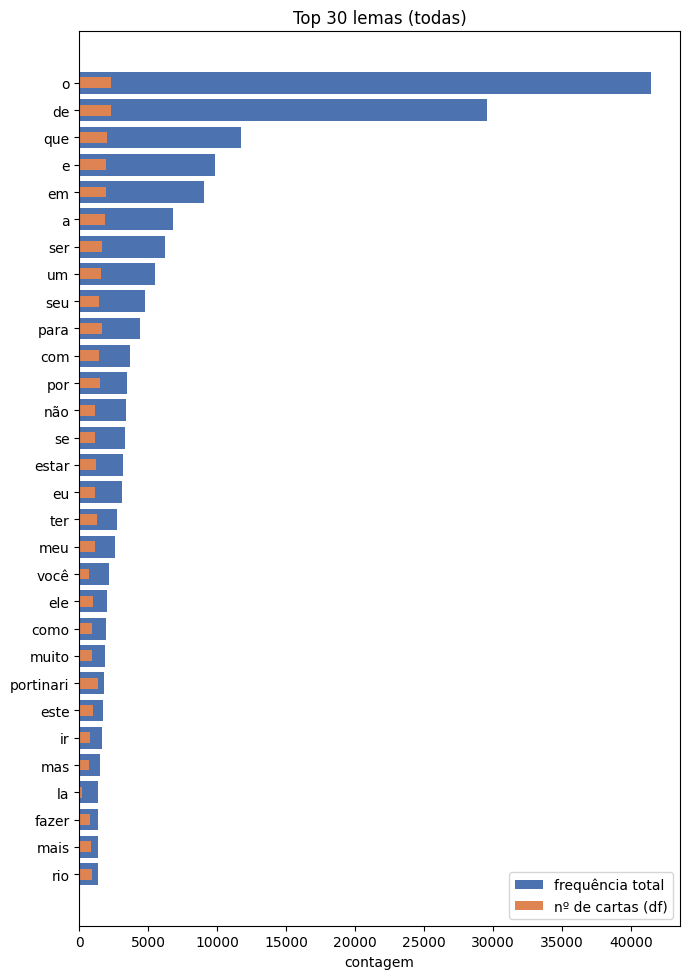

In [21]:
print(f"Top {TOP} {UNIDADE} (todas):")
display(freq_total.head(TOP)[["palavra", "freq", "df"]])
fig_top_palavras(freq_total, f"Top {TOP} {UNIDADE} (todas)", SAIDA / f"top_palavras_todas{SUF}.png", TOP)

Top 30 lemas de conteúdo (sem stopwords):


,palavra,freq,df
0,portinari,1803,1374
1,la,1394,211
2,rio,1339,940
3,dia,1101,656
4,amigo,1098,663
5,paulo,986,455
6,carta,895,639
7,y,865,132
8,público,835,66
9,trabalho,790,424


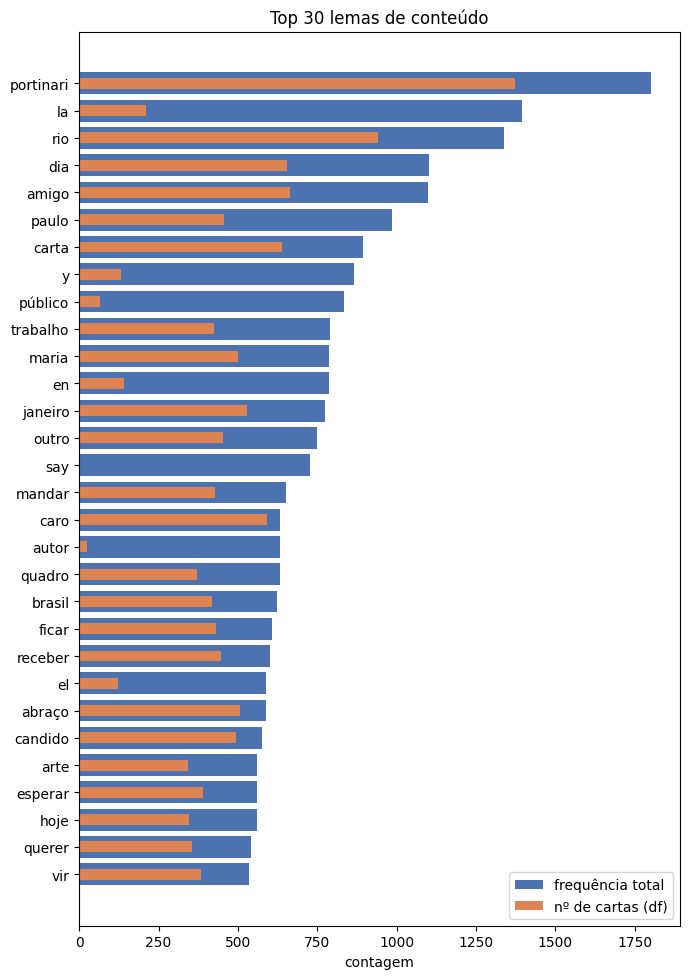

In [22]:
print(f"Top {TOP} {UNIDADE} de conteúdo (sem stopwords):")
display(freq_conteudo.head(TOP)[["palavra", "freq", "df"]])
fig_top_palavras(freq_conteudo, f"Top {TOP} {UNIDADE} de conteúdo", SAIDA / f"top_palavras_conteudo{SUF}.png", TOP)

### 2.4 Nuvem de palavras (palavras de conteúdo)

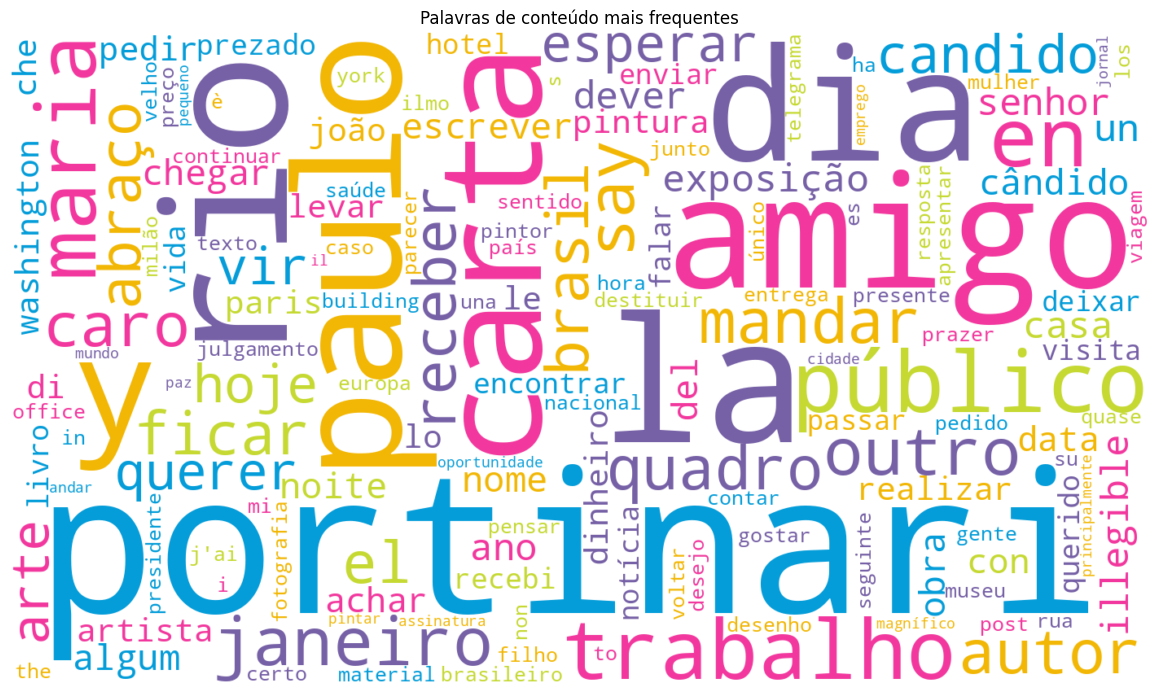

In [23]:
nuvem_de_frequencias(
    freq_conteudo.head(150).set_index("palavra")["freq"],
    SAIDA / "nuvem_palavras.png", FONTE_NUVEM,
    titulo="Palavras de conteúdo mais frequentes",
)

## 4. Análise morfológica (spaCy)

Esta parte usa o spaCy para obter, de cada palavra, o **lema**, a **classe gramatical (UPOS)** e os **traços morfológicos** (ex.: `Gender=Masc|Number=Sing`). Instale com:

```
pip install spacy
python -m spacy download pt_core_news_lg
```

Pontos de atenção:

- Não há separador `/` de verso nos dados. Antes de passar o texto ao spaCy, `texto_para_spacy` rebaixa para minúscula as maiúsculas que não iniciam frase (depois de `.`, `!`, `?` ou `…`); senão a maiúscula no início de cada verso leva o etiquetador a confundir palavras comuns com nomes próprios (PROPN). Detalhes na docstring da função.
- `is_stop` vem da lista de stopwords do **spaCy**, que difere da lista usada na parte 2. Os totais "sem stopwords" não batem entre as duas partes.
- O etiquetador erra mais em verso (inversões, elipses, formas arcaicas). Confira uma amostra de `tokens_spacy.csv`. O modelo `lg` é mais preciso que o `sm`.
- Palavras sem nenhum traço (preposições, advérbios, conjunções) são normais: o esquema UD não lhes atribui morfologia.

### Funções: morfologia e análise por classe gramatical

Constantes (nomes das classes, traços a examinar em cada classe) e as funções que desenham os gráficos morfológicos e geram a nuvem e as frequências de cada classe.

In [24]:
NOMES_CLASSES = { #associa cada etiqueta UPOS (Universal Part-of-Speech) a um nome em português.
    "NOUN": "substantivos", "VERB": "verbos", "ADJ": "adjetivos", "ADV": "advérbios",
    "PROPN": "nomes próprios", "PRON": "pronomes", "DET": "determinantes", "ADP": "preposições",
    "AUX": "verbos auxiliares", "CCONJ": "conjunções coordenativas", "SCONJ": "conjunções subordinativas",
    "NUM": "numerais", "INTJ": "interjeições", "PART": "partículas", "X": "outros",
}
#categorias para análise
PRINCIPAIS = ["NOUN", "VERB", "ADJ", "ADV", "PROPN", "PRON"] 

# Define quais traços morfológicos são relevantes para cada classe gramatical.
FOCOS_MORF = [ 
    ("VERB", ["VerbForm", "Tense", "Mood", "Person", "Number"]),
    ("AUX", ["VerbForm", "Tense", "Mood", "Person", "Number"]),
    ("NOUN", ["Gender", "Number"]),
    ("ADJ", ["Gender", "Number", "Degree"]),
    ("PRON", ["Person", "Number", "PronType"]),
    ("DET", ["Gender", "Number", "Definite"]),
]
#então em focos morf para cada classe gramatical vamos obervar apenas as determinados traços mofológicos

#gráfico de barras horizontais comparando a frequência (nº de palavras) de cada classe gramatical em dois conjuntos: todas as palavras e as palavras após a remoção de stopwords.
def fig_morf_pos(tab_pos, caminho, mostrar=True):
    t = tab_pos.sort_values("n_todas")
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(t) + 1.5))
    ax.barh(y + 0.2, t["n_todas"], height=0.4, color="#4C72B0", label="todas as palavras")
    ax.barh(y - 0.2, t["n_sem_stop"], height=0.4, color="#DD8452", label="sem stopwords (spaCy)")
    ax.set_yticks(y)
    ax.set_yticklabels(t.index)
    ax.set_xlabel("frequência (nº de palavras na classe)")
    ax.set_title("Classes gramaticais (UPOS)")
    ax.legend(loc="lower right")
    finalizar(fig, caminho, mostrar)

# Essa função gera um gráfico com os traços morfológicos mais frequentes.
def fig_morf_tracos(tab_traco, caminho, top, mostrar=True):
    t = tab_traco.sort_values("n_todas", ascending=False).head(top).iloc[::-1]
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(t) + 1.5))
    ax.barh(y + 0.2, t["n_todas"], height=0.4, color="#4C72B0", label="todas as palavras")
    ax.barh(y - 0.2, t["n_sem_stop"], height=0.4, color="#DD8452", label="sem stopwords (spaCy)")
    ax.set_yticks(y)
    ax.set_yticklabels(t.index, fontsize=8)
    ax.set_xlabel("nº de palavras com o traço")
    ax.set_title(f"Top {len(t)} traços morfológicos")
    ax.legend(loc="lower right")
    finalizar(fig, caminho, mostrar)

# Essa função se concentra nas características morfológicas dos verbos e auxiliares.
def fig_morf_verbos(m, caminho, mostrar=True):
    """Distribuição de VerbForm, Tense e Mood nas formas verbais (VERB + AUX)."""
    v = m[m["pos"].isin(["VERB", "AUX"])]
    feats = [f for f in ("VerbForm", "Tense", "Mood") if (v["feature"] == f).any()]
    if not feats:
        return
    fig, axes = plt.subplots(1, len(feats), figsize=(4.2 * len(feats), 3.8), squeeze=False)
    for ax, f in zip(axes[0], feats):
        c = v.loc[v["feature"] == f, "value"].value_counts()
        ax.bar(c.index, c.values / c.sum(), color="#55A868")
        ax.set_title(f"{f} (verbos e auxiliares)")
        ax.set_ylabel("proporção")
        ax.tick_params(axis="x", rotation=45)
    finalizar(fig, caminho, mostrar)


def analise_por_classe(tok, saida, top=30, fonte=None, usar_formas=False, sem_stopwords=False,
                       classes=None, min_palavras=10, exibir=None):
    """Para cada classe gramatical: tabela de frequências, barras das `top` palavras e nuvem.
    Salva tudo em <saida>/classes/ e exibe só as classes em `exibir` (None = todas).
    Retorna (dicionário classe -> tabela, tabela-resumo)."""
    col = "token" if usar_formas else "lema"
    escopo = "formas" if usar_formas else "lemas"               #formas usa o lema
    base = tok[~tok["is_stop"]] if sem_stopwords else tok       #sem_stopwords deixa de usar as stpowords false
    pasta = saida / "classes"
    pasta.mkdir(parents=True, exist_ok=True)

    tabelas, resumo = {}, []
    for pos in base["pos"].value_counts().index:
        if classes and pos not in classes:
            continue
        sub = base[base["pos"] == pos]
        if len(sub) < min_palavras:
            continue
        g = (
            sub.groupby(col)
            .agg(freq=("token", "size"), df=("id", "nunique"))
            .reset_index()
            .rename(columns={col: "palavra"})
            .sort_values(["freq", "df", "palavra"], ascending=[False, False, True])
            .reset_index(drop=True)
        )
        g["rank"] = g.index + 1
        g.to_csv(pasta / f"freq_{pos}.csv", index=False)
        tabelas[pos] = g

        nome = NOMES_CLASSES.get(pos, pos)
        mostrar = exibir is None or pos in exibir
        if mostrar:
            print(f"\n{'=' * 60}\n{nome} ({pos}): {len(sub)} palavras, {len(g)} {escopo} distintos\n{'=' * 60}")
        fig_top_palavras(g, f"{nome} ({pos}): top {min(top, len(g))} {escopo}",
                         pasta / f"freq_{pos}.png", top, mostrar=mostrar)
        nuvem_de_frequencias(g.set_index("palavra")["freq"], pasta / f"nuvem_{pos}.png", fonte,
                             max_palavras=100, titulo=f"{nome} ({pos})", mostrar=mostrar)
        resumo.append({
            "classe": pos, "nome": nome, "palavras": len(sub), f"{escopo}_distintos": len(g),
            "mais_frequentes": ", ".join(f"{w} ({f})" for w, f in zip(g["palavra"].head(5), g["freq"].head(5))),
        })

    # painel com as classes principais, para slide
    pan = [p for p in PRINCIPAIS if p in tabelas]
    if pan:
        n_col = 3 if len(pan) > 4 else 2
        n_lin = int(np.ceil(len(pan) / n_col))
        fig, axes = plt.subplots(n_lin, n_col, figsize=(5.2 * n_col, 4.2 * n_lin), squeeze=False)
        for ax, pos in zip(axes.ravel(), pan):
            t = tabelas[pos].head(10).iloc[::-1]
            ax.barh(t["palavra"], t["freq"], color="#4C72B0")
            ax.set_title(f"{NOMES_CLASSES.get(pos, pos)} ({pos})", fontsize=10)
            ax.tick_params(labelsize=8)
        for ax in axes.ravel()[len(pan):]:
            ax.axis("off")
        fig.suptitle(f"Top 10 {escopo} por classe gramatical")
        print(f"\n{'=' * 60}\nPainel das classes principais\n{'=' * 60}")
        finalizar(fig, saida / "classes_painel_frequencias.png")
    return tabelas, pd.DataFrame(resumo)

In [25]:
# a tabela foi criada na parte 1; aqui ela só é descartada se RODAR_SPACY = False (parte 4 pulada)
tok = tok if RODAR_SPACY else None

if tok is not None:
    tok.to_csv(SAIDA / "tokens_spacy.csv", index=False)
    print(f"{len(tok)} palavras alfabéticas; {int((~tok['is_stop']).sum())} sem stopwords (spaCy); "
          f"{int((tok['morph'] == '').sum())} sem nenhum traço morfológico.")
    display(tok.head(15))

380648 palavras alfabéticas; 195358 sem stopwords (spaCy); 80565 sem nenhum traço morfológico.


,id,token,lema,pos,morph,is_stop
0,CO_CO-6324.A,caro,caro,PROPN,Gender=Masc|Number=Sing,False
1,CO_CO-6324.A,carlos,carlos,PROPN,Gender=Masc|Number=Sing,False
2,CO_CO-6324.A,logo,logo,ADV,,True
3,CO_CO-6324.A,que,que,SCONJ,,True
4,CO_CO-6324.A,cheguei,cheguei,VERB,Mood=Ind|Number=Sing|Person=1|Tense=Past|VerbForm=Fin,False
5,CO_CO-6324.A,aqui,aqui,ADV,,True
6,CO_CO-6324.A,souvi,souvi,VERB,Mood=Ind|Number=Plur|Person=3|Tense=Past|VerbForm=Fin,False
7,CO_CO-6324.A,por,por,ADP,,True
8,CO_CO-6324.A,três,três,NUM,NumType=Card,True
9,CO_CO-6324.A,depois,depois,ADV,,True


### 4.1 Classes gramaticais (UPOS)

Frequência (nº de palavras) de cada classe, entre todas as palavras e entre as palavras de conteúdo (sem stopwords do spaCy). A tabela traz também a proporção de cada classe.

,n_todas,n_sem_stop,prop_todas,prop_sem_stop
pos,,,,
NOUN,68214,63706,0.179,0.326
PROPN,67446,64384,0.177,0.330
ADP,54907,1557,0.144,0.008
VERB,45531,38279,0.120,0.196
DET,40062,1046,0.105,0.005
ADV,22515,4399,0.059,0.023
PRON,21607,1345,0.057,0.007
ADJ,19033,16053,0.050,0.082
SCONJ,14312,281,0.038,0.001


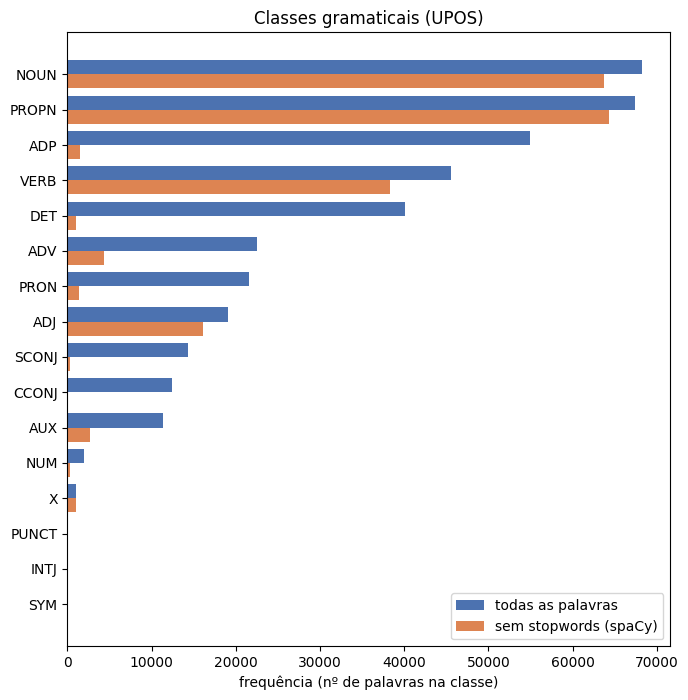

In [26]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    p_todas = tok["pos"].value_counts()
    p_sem = tok.loc[~tok["is_stop"], "pos"].value_counts()
    tab_pos = pd.DataFrame({"n_todas": p_todas, "n_sem_stop": p_sem}).fillna(0).astype(int)
    tab_pos["prop_todas"] = tab_pos["n_todas"] / tab_pos["n_todas"].sum()
    tab_pos["prop_sem_stop"] = tab_pos["n_sem_stop"] / max(tab_pos["n_sem_stop"].sum(), 1)
    tab_pos = tab_pos.sort_values("n_todas", ascending=False)
    tab_pos.rename_axis("pos").to_csv(SAIDA / "morf_pos.csv")
    display(tab_pos)

    fig_morf_pos(tab_pos, SAIDA / "morf_pos.png")

### 4.2 Traços morfológicos

Contagem dos traços `Feature=Valor`. A coluna `n_sem_stop` conta só palavras que não são stopwords (spaCy), como no código usado pelo grupo. A coluna `prop_palavras` é a fração das palavras do corpus que têm o traço.

Atenção: a contagem agregada mistura classes (um `Number=Sing` de substantivo e um de verbo contam igual).

,n_todas,n_sem_stop,prop_palavras
traco,,,
Number=Sing,235210,149591,0.618
Gender=Masc,128047,74688,0.336
Gender=Fem,77374,45080,0.203
PronType=Art,46212,533,0.121
Number=Plur,44525,27264,0.117
Definite=Def,41023,460,0.108
VerbForm=Fin,35806,23496,0.094
Person=3,32555,17705,0.086
Mood=Ind,31472,19638,0.083


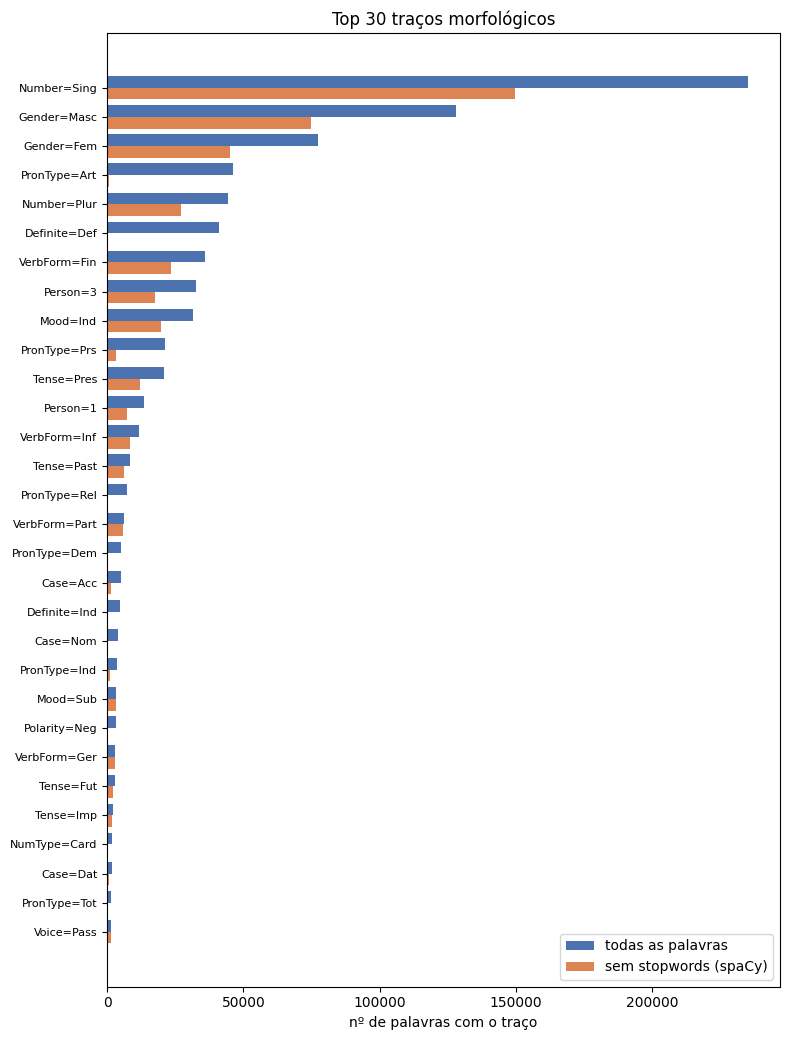

In [27]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    m = explodir_tracos(tok)

    c_todas = m["traco"].value_counts()
    c_sem = m.loc[~m["is_stop"], "traco"].value_counts()
    tab_traco = pd.DataFrame({"n_todas": c_todas, "n_sem_stop": c_sem}).fillna(0).astype(int)
    tab_traco["prop_palavras"] = tab_traco["n_todas"] / len(tok)
    tab_traco = tab_traco.sort_values("n_todas", ascending=False)
    tab_traco.rename_axis("traco").to_csv(SAIDA / "morf_tracos.csv")

    display(tab_traco.head(TOP))
    fig_morf_tracos(tab_traco, SAIDA / "morf_tracos_top.png", TOP)

## Observações e limitações

- **Lemas e etiquetas do spaCy são estimativas**, não verdade de referência: em português poético (inversões, elipses, formas arcaicas) o etiquetador erra mais. Lemas de contrações aparecem separados ("em o", "de ela").
- **Lemas (parte 2):** com `LEMAS = True`, as contagens dependem do lematizador do spaCy; lemas errados, ou formas que ele não reconhece e deixa como estão, alteram o ranking. Contrações são separadas nas palavras componentes (`no` → `em`, `o`), então `n_tokens` conta essas palavras.
- **Poucos dados**: com ≈ 87 palavras por poema, a maioria das palavras tem frequência 1 ou 2. Proporções por classe com poucas ocorrências são instáveis.
- **Maiúsculas:** os poemas não têm `/` entre os versos, então cada verso começa em maiúscula. `texto_para_spacy` rebaixa as maiúsculas que não iniciam frase para o spaCy não confundir palavras comuns com PROPN; o efeito colateral é que nomes próprios reais no meio do verso (ex.: "Brodowski") também perdem a maiúscula e podem deixar de ser etiquetados como PROPN.
- **A lista de stopwords da parte 2 é própria**; a da parte 4 é a do spaCy.
- **Cartas (`CORPUS = "carta"`):**
  - `[ilegível]` vira `…` (que o tokenizador ignora) e é contado em `n_ilegiveis`; o campo `total_ilegiveis` do JSONL não é usado, porque pode divergir do texto (o notebook avisa quantas cartas divergem). Outras marcas entre colchetes são listadas na carga, mas **não** tratadas: viram palavras.
  - As métricas de sentença (`n_sentencas`, `tokens_por_sentenca`) são omitidas, pois dependem de pontuação que o texto diplomático quase não tem.
  - Sem a normalização de maiúsculas (padrão para cartas), o spaCy vê o texto como está. Compare as duas opções em uma amostra (`NORMALIZAR_MAIUSCULAS`).
  - A transcrição preserva grafia original, abreviações e erros de leitura: lemas e classes erram mais que nos poemas. Os limiares `MIN_PALAVRAS_LEGIVEIS` e `MAX_PROP_ILEGIVEL` são ponto de partida; ajuste olhando `prop_ilegivel` em `metricas_por_poema_*.csv` e a lista `cartas_descartadas.csv`.
  - Abreviações com ponto ("B.H.") são separadas pelo tokenizador em letras soltas ("b", "h").